# Benchmark: predictive intervals and conditional quantiles

A point prediction says where the response is expected; an interval says how
far from it the response can fall. This study compares 80% predictive
intervals, the estimated 10% and 90% conditional quantiles, on data whose
noise changes with the predictors in three ways:

* **hetero**: Gaussian noise whose standard deviation grows from 0.2 to 1.0
  with $|x_1|$;
* **skewed**: right-skewed (gamma) noise whose scale grows with $x_2$;
* **heavy**: Student-$t$ noise with 3 degrees of freedom whose scale grows
  with $x_2$.

The mean is $\sin 2x_1 + 0.5x_2$ in all three, with three irrelevant
predictors, 1,000 training rows and 5,000 test rows.

mboostrs enters three ways: two quantile regressions (`family=Quantile(tau)`
for 0.1 and 0.9), a Gaussian location-scale model (`gamboostLSS` with
`GaussianLSS`, whose 10% and 90% quantiles follow from the fitted mean and
standard deviation), and conformalized quantile regression
(`conformal_interval(method="cqr")`), which widens or narrows a quantile band
by an amount calibrated on held-out rows so that its marginal coverage is
guaranteed. The competitors are the quantile specialists (qgam, the R
package for quantile GAMs; quantile regression forests; the quantile losses
of LightGBM, XGBoost, CatBoost and APLR) and the distributional specialists
(gamlss and mgcv's `gaulss` Gaussian location-scale GAM, and NGBoost with a
normal distribution).

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | how well each method's 80% interval matches the true conditional distribution |
| **Observed response** | simulated continuous response with heteroscedastic Gaussian, skewed or heavy-tailed noise |
| **Estimand** | interval score, marginal coverage, conditional coverage error (mean absolute deviation from 80% over deciles of the true noise scale), mean width, RMSE of the two estimated quantiles against the true ones |
| **Units** | response units; proportions |
| **Sampling unit** | one row; 1,000 training and 5,000 test rows per seed |
| **Dependence** | independent rows |
| **Split / resampling unit** | a fresh test sample from the same design |
| **Tuning** | mboostrs: 5-fold CV of the step count (the LSS model: of the total step count); trees: early stopping on a 20% validation split over a size grid; NGBoost: validation early stopping; qgam, gamlss, mgcv: their own smoothing selection; quantile forest, APLR: defaults |
| **Uncertainty** | mean and standard error over 8 seeds |
| **Claim type** | methodological |
:::

The **interval score** is the width of the interval plus $2/\alpha = 10$
times the distance by which an observation falls outside it. It is a proper
scoring rule for a central 80% interval: it is smallest in expectation for
the true 10% and 90% quantiles, so a method cannot improve it by making
intervals too wide or too narrow. Marginal coverage alone can conceal intervals that are too wide in some
regions and too narrow in others. The interval score also measures their
width and the distances of observations outside them.

In [1]:
import json
from pathlib import Path

import altair as alt
import polars as pl

bench = json.loads(Path("bench_uncertainty.json").read_text())
rows = [r for r in bench["results"] if "error" not in r]
failed = [r for r in bench["results"] if "error" in r]
intervals = pl.DataFrame(rows, infer_schema_length=None)
f"{intervals.height} interval sets; {len(failed)} failed"

'288 interval sets; 0 failed'

In [2]:
COLUMNS = ["interval_score", "coverage", "conditional_coverage_error", "width",
           "quantile_rmse", "seconds"]
table = (intervals.group_by("task", "method")
         .agg([pl.col(c).mean().alias(c) for c in COLUMNS]
              + [(pl.col("interval_score").std() / pl.len().sqrt()).alias("score se")])
         .sort("task", "interval_score"))


def value(task, method, column):
    return float(table.filter((pl.col("task") == task) & (pl.col("method") == method))[column][0])


def best(task):
    return table.filter(pl.col("task") == task)["method"][0]


from bench_tables import table as annotated

task_label = {"hetero": "hetero: Gaussian noise, sd grows with |x1|",
              "skewed": "skewed: gamma noise, scale grows with x2",
              "heavy": "heavy: t(3) noise, scale grows with x2"}

In [3]:
annotated(
    table.with_columns(pl.col("task").replace(task_label).alias("noise"))
    .select("noise", "method", "interval_score", "score se", "coverage",
            "conditional_coverage_error", "width", "quantile_rmse", "seconds"),
    title="80% predictive intervals under three kinds of noise",
    subtitle="Mean over 8 seeds; 1,000 training rows, 5,000 test rows",
    group="noise",
    labels={"interval_score": "interval score ↓", "score se": "se",
            "coverage": "coverage", "conditional_coverage_error": "cond. error ↓",
            "width": "width", "quantile_rmse": "quantile RMSE ↓", "seconds": "s"},
    better={"interval_score": "min", "conditional_coverage_error": "min",
            "quantile_rmse": "min"},
    formats={"seconds": 1},
    notes=["interval score: width of the 10%–90% interval plus 2/0.2 times the distance by "
           "which a test response falls outside it, averaged over test rows; it rewards "
           "narrow intervals that still contain the response. se: its standard error over "
           "seeds. coverage: share of test responses inside the interval (nominal 0.80). "
           "cond. error: mean absolute deviation of the coverage from 0.80 over deciles of "
           "the true noise scale, which is large for an interval of constant width.",
           "width: mean interval width in response units. quantile RMSE: root mean squared "
           "error of the estimated 10% and 90% quantiles against the true ones. s: mean "
           "seconds per fit including tuning. Bold: best within each kind of noise. "
           "Source: bench_uncertainty.json, written by benches/bench_uncertainty.py."])

GT(_tbl_data=shape: (36, 9)
┌────────────┬───────────┬───────────┬──────────┬───┬───────────┬──────────┬───────────┬───────────┐
│ noise      ┆ method    ┆ interval_ ┆ score se ┆ … ┆ condition ┆ width    ┆ quantile_ ┆ seconds   │
│ ---        ┆ ---       ┆ score     ┆ ---      ┆   ┆ al_covera ┆ ---      ┆ rmse      ┆ ---       │
│ str        ┆ str       ┆ ---       ┆ f64      ┆   ┆ ge_error  ┆ f64      ┆ ---       ┆ f64       │
│            ┆           ┆ f64       ┆          ┆   ┆ ---       ┆          ┆ f64       ┆           │
│            ┆           ┆           ┆          ┆   ┆ f64       ┆          ┆           ┆           │
╞════════════╪═══════════╪═══════════╪══════════╪═══╪═══════════╪══════════╪═══════════╪═══════════╡
│ heavy:     ┆ mboostrs  ┆ 3.587388  ┆ 0.044622 ┆ … ┆ 0.0245    ┆ 1.930792 ┆ 0.167424  ┆ 2.563932  │
│ t(3)       ┆ quantile  ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ noise,     ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ scale      ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ grows…     ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ heavy:     ┆ qgam      ┆ 3.599713  ┆ 0.043306 ┆ … ┆ 0.03175   ┆ 2.145843 ┆ 0.19568   ┆ 7.472303  │
│ t(3)       ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ noise,     ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ scale      ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ grows…     ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ heavy:     ┆ mboostrs  ┆ 3.61391   ┆ 0.051735 ┆ … ┆ 0.028775  ┆ 2.029817 ┆ 0.218352  ┆ 2.999991  │
│ t(3)       ┆ CQR       ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ noise,     ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ scale      ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ grows…     ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ heavy:     ┆ APLR      ┆ 3.62131   ┆ 0.042342 ┆ … ┆ 0.023725  ┆ 1.989197 ┆ 0.230323  ┆ 11.319068 │
│ t(3)       ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ noise,     ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ scale      ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ grows…     ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ heavy:     ┆ mboostrs  ┆ 3.685871  ┆ 0.049534 ┆ … ┆ 0.061975  ┆ 2.485838 ┆ 0.350103  ┆ 4.21466   │
│ t(3)       ┆ LSS       ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ noise,     ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ scale      ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ grows…     ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ …          ┆ …         ┆ …         ┆ …        ┆ … ┆ …         ┆ …        ┆ …         ┆ …         │
│ skewed:    ┆ XGBoost   ┆ 1.660009  ┆ 0.016498 ┆ … ┆ 0.04605   ┆ 1.077554 ┆ 0.182997  ┆ 1.348136  │
│ gamma      ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ noise,     ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ scale gro… ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ skewed:    ┆ LightGBM  ┆ 1.66642   ┆ 0.013138 ┆ … ┆ 0.05775   ┆ 1.042302 ┆ 0.187751  ┆ 0.865217  │
│ gamma      ┆           ┆           ┆          ┆   ┆           ┆          ┆           ┆           │
│ noise,     ┆           ┆       

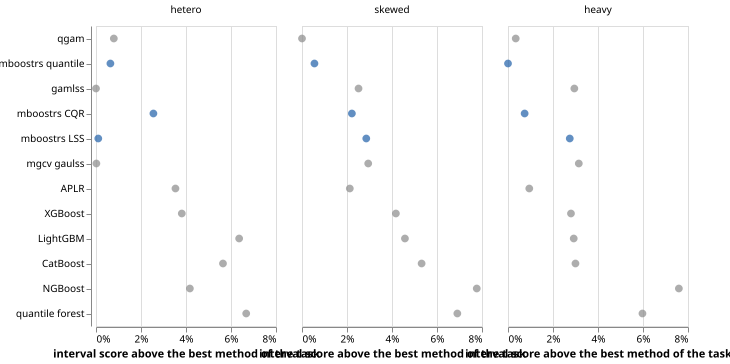

In [4]:
# Interval score relative to the best method of each task: 0 is the best.
relative = table.with_columns(
    (pl.col("interval_score") / pl.col("interval_score").min().over("task") - 1).alias("excess"),
    pl.col("method").str.starts_with("mboostrs").alias("mboostrs"))
display(alt.Chart(relative).mark_point(filled=True, size=60).encode(
    x=alt.X("excess:Q", title="interval score above the best method of the task",
            axis=alt.Axis(format="%")),
    y=alt.Y("method:N", sort=alt.EncodingSortField("excess", op="mean"), title=None),
    color=alt.Color("mboostrs:N", legend=None, scale=alt.Scale(range=["#8a8a8a", "#1f5fa8"])),
    column=alt.Column("task:N", title=None, sort=["hetero", "skewed", "heavy"]),
).properties(width=180, height=300))

## Results

With Gaussian noise the location-scale models are the right model and lead:
{eval}`best("hetero")` has interval score
{eval}`round(value("hetero", best("hetero"), "interval_score"), 3)`, mboostrs'
`GaussianLSS` {eval}`round(value("hetero", "mboostrs LSS", "interval_score"), 3)`
and its two quantile regressions
{eval}`round(value("hetero", "mboostrs quantile", "interval_score"), 3)`.
With skewed noise a normal distribution is the wrong shape, and the
location-scale models over-cover
({eval}`round(100 * value("skewed", "mboostrs LSS", "coverage"))`% for the
mboostrs model, {eval}`round(100 * value("skewed", "gamlss", "coverage"))`% for
gamlss): the quantile regressions, which assume no shape, lead, with qgam at
{eval}`round(value("skewed", "qgam", "interval_score"), 3)` and mboostrs
at {eval}`round(value("skewed", "mboostrs quantile", "interval_score"), 3)`.
With heavy tails mboostrs' quantile regressions have the lowest interval score
({eval}`round(value("heavy", "mboostrs quantile", "interval_score"), 3)`,
qgam {eval}`round(value("heavy", "qgam", "interval_score"), 3)`).

The additive quantile regressions (mboostrs, qgam) estimate the true
quantiles more accurately than the tree methods in every task, with a
quantile RMSE about 40% lower (in the Gaussian task
{eval}`round(value("hetero", "mboostrs quantile", "quantile_rmse"), 3)` for
mboostrs against {eval}`round(value("hetero", "XGBoost", "quantile_rmse"), 3)`
for XGBoost, the best tree method). The tree methods' intervals also
under-cover: LightGBM's cover
{eval}`round(100 * value("hetero", "LightGBM", "coverage"))`% and the quantile
forest's {eval}`round(100 * value("hetero", "quantile forest", "coverage"))`% in
the Gaussian task. The Gaussian location-scale models are accurate when the
noise is Gaussian and among the least accurate with heavy tails
(quantile RMSE {eval}`round(value("heavy", "gamlss", "quantile_rmse"), 3)` for
gamlss).

Conformalized quantile regression is the only method with guaranteed
coverage, and its coverage is within a point of 80% in all three tasks
({eval}`round(100 * value("hetero", "mboostrs CQR", "coverage"))`%,
{eval}`round(100 * value("skewed", "mboostrs CQR", "coverage"))`%,
{eval}`round(100 * value("heavy", "mboostrs CQR", "coverage"))`%). The
guarantee costs sharpness: half the rows calibrate, so the quantiles are
fitted on 500, and its interval score is behind the quantile regressions fitted
on all 1,000.

## Package fixes

The first run found two defects in `conformal_interval(method="cqr")`, fixed
before the results above were produced:

* **It raised on skewed and heavy-tailed data.** When the calibrated
  correction is negative it narrows the band, and at rows where the two
  quantile fits are closer than twice the correction the lower end passed the
  upper and the result was refused. It failed in 5 of 24 runs. Crossed
  quantile fits are now ordered, and an inverted band is returned as the
  single point at its middle, which keeps the coverage guarantee (the
  conformal set there is empty, and any set contains it).
* **Its quantile fits reused the Gaussian model's step count.** The check
  loss moves by a step of `nu` times a sign and needs more steps; each
  quantile's step count is now cross-validated on the training half. The
  interval score fell from 2.238 to
  {eval}`round(value("hetero", "mboostrs CQR", "interval_score"), 3)` in the
  Gaussian task, 1.675 to
  {eval}`round(value("skewed", "mboostrs CQR", "interval_score"), 3)` with
  skewed noise and 3.707 to
  {eval}`round(value("heavy", "mboostrs CQR", "interval_score"), 3)` with heavy
  tails.

## Summary

| Noise | Leader | mboostrs |
|---|---|---|
| Gaussian, changing scale | gamlss, mgcv `gaulss` | `GaussianLSS` within 0.2% of the leader |
| Skewed | qgam | quantile regression within 1% of qgam |
| Heavy-tailed | mboostrs quantile regression | leads; qgam second |
| Guaranteed coverage | mboostrs CQR (no other method here offers it) | within a point of nominal in every task |

A location-scale model is the best choice when its distribution is right and
a poor one when it is not; quantile regression needs no distribution and
loses little when one would have fitted. `mb.gamboostLSS` offers skewed and
heavy-tailed families (for example `StudentTLSS`, `GammaLSS`, `BCCGLSS`)
that this study did not try.

## Limitations

The designs have one source of heteroscedasticity each and additive means,
which favours the additive methods. Each method's quantile levels were fitted
separately where the library does so (mboostrs, qgam, LightGBM, APLR), which
can let the two quantiles cross; one test row of one LightGBM fit had crossed
quantiles, and none for the other methods. The
results are in `docs/book/cases/bench_uncertainty.json`, produced by
`benches/bench_uncertainty.py`.